Import libraries and load dataset

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from urllib.parse import urlparse

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


Extract and Clean Domain Names

In [5]:
def clean_domain(domain):
    if pd.isna(domain):
        return None

    domain = str(domain).lower().strip()

    domain = re.sub(r'^https?://', '', domain)
    domain = domain.replace('www.', '')

    return domain.split('/')[0]

df['clean_domain'] = df['source_domain'].apply(clean_domain)

display(df[['source_domain', 'clean_domain']].head())

,source_domain,clean_domain
0,toofab.com,toofab.com
1,www.today.com,today.com
2,www.etonline.com,etonline.com
3,www.dailymail.co.uk,dailymail.co.uk
4,www.zerchoo.com,zerchoo.com


analyse frequently publishing domains

In [6]:
domain_frequency = df['clean_domain'].value_counts()

print("Most Frequent News Domains:")
display(domain_frequency.head(15))

Most Frequent News Domains:


clean_domain
people.com               1786
dailymail.co.uk           964
en.wikipedia.org          741
usmagazine.com            709
etonline.com              666
longroom.com              562
hollywoodlife.com         524
usatoday.com              332
hollywoodreporter.com     330
variety.com               304
ew.com                    255
elle.com                  205
web.archive.org           204
billboard.com             197
today.com                 195
Name: count, dtype: int64

compare fake and real news by domain

In [7]:
df['label'] = df['real'].map({
    1: 'Real',
    0: 'Fake'
})

domain_analysis = pd.crosstab(
    df['clean_domain'],
    df['label']
)

domain_analysis['Total'] = domain_analysis.sum(axis=1)

domain_analysis['Fake_Percentage'] = (
    domain_analysis['Fake'] /
    domain_analysis['Total'] * 100
)

domain_analysis['Real_Percentage'] = (
    domain_analysis['Real'] /
    domain_analysis['Total'] * 100
)

display(domain_analysis.sort_values(
    'Fake_Percentage',
    ascending=False
))

label,Fake,Real,Total,Fake_Percentage,Real_Percentage
clean_domain,,,,,
100percentfedup.com,1,0,1,100.0,0.0
24trueinfoamerica.com,1,0,1,100.0,0.0
2medusa.com,1,0,1,100.0,0.0
zerohedge.com,1,0,1,100.0,0.0
zimbabwe-today.com,1,0,1,100.0,0.0
...,...,...,...,...,...
wvlc.com,0,4,4,0.0,100.0
wushack.com,0,3,3,0.0,100.0
wusa9.com,0,4,4,0.0,100.0


load external domain credibility dataset

In [8]:
cred = pd.read_csv("cred1_current.csv")

print("External Credibility Dataset:")
display(cred.head())

External Credibility Dataset:


,domain,category,credibility_score,sources,iffy_factual,iffy_bias,iffy_score,tranco_rank,domain_age_years,domain_registered,factcheck_claims,safe_browsing_flagged,score_cat,score_iffy,score_tranco,score_age,score_factcheck,score_safebrowsing
0,100percentfedup.com,mixed,0.173,2,L,FN,0.1,200698.0,14.0,2012-03-13T15:59:26Z,NaN,NaN,0.20,0.10,0.35,0.20,0.20,0.20
1,10news.one,unreliable,0.090,1,L,FN,0.1,NaN,NaN,NaN,NaN,NaN,0.10,0.10,0.10,0.10,0.10,0.10
2,12minutos.com,unreliable,0.090,1,L,FN,0.1,NaN,18.2,2008-01-13T13:49:04Z,NaN,NaN,0.10,0.10,0.10,0.10,0.10,0.10
3,163.com,unreliable,0.105,1,M,FN,0.2,418.0,28.5,1997-09-15T04:00:00Z,NaN,NaN,0.10,0.20,0.10,0.10,0.10,0.10
4,16wmpo.com,fake,0.045,1,NaN,NaN,NaN,NaN,8.0,2018-03-03T19:22:21Z,NaN,NaN,0.05,0.05,0.05,0.05,0.05,0.05


clean external domain names

In [10]:
cred['clean_domain'] = cred['domain'].apply(clean_domain)

display(cred[['domain', 'clean_domain']].head())

,domain,clean_domain
0,100percentfedup.com,100percentfedup.com
1,10news.one,10news.one
2,12minutos.com,12minutos.com
3,163.com,163.com
4,16wmpo.com,16wmpo.com


merge internal and external credibility data

In [11]:
merged_df = df.merge(
    cred,
    on='clean_domain',
    how='left',
    suffixes=('_news', '_external')
)

display(merged_df.head())

,title,news_url,source_domain,tweet_num,real,clean_domain,label,domain,category,credibility_score,...,domain_age_years,domain_registered,factcheck_claims,safe_browsing_flagged,score_cat,score_iffy,score_tranco,score_age,score_factcheck,score_safebrowsing
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1,toofab.com,Real,toofab.com,unreliable,0.11,...,22.5,2003-09-20T14:01:04Z,NaN,NaN,0.1,0.2,0.2,0.1,0.1,0.1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1,today.com,Real,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1,etonline.com,Real,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1,dailymail.co.uk,Real,dailymail.co.uk,unreliable,0.09,...,30.8,1995-06-16T23:44:06Z,NaN,NaN,0.1,0.1,0.1,0.1,0.1,0.1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1,zerchoo.com,Real,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


analtyse externally verified domain credibility

In [12]:
credibility_columns = [
    col for col in [
        'clean_domain',
        'label',
        'credibility_score',
        'iffy_factual',
        'factcheck_claims',
        'domain_age_years'
    ]
    if col in merged_df.columns
]

display(merged_df[credibility_columns].head(20))

,clean_domain,label,credibility_score,iffy_factual,factcheck_claims,domain_age_years
0,toofab.com,Real,0.11,M,NaN,22.5
1,today.com,Real,NaN,NaN,NaN,NaN
2,etonline.com,Real,NaN,NaN,NaN,NaN
3,dailymail.co.uk,Real,0.09,L,NaN,30.8
4,zerchoo.com,Real,NaN,NaN,NaN,NaN
5,intouchweekly.com,Fake,NaN,NaN,NaN,NaN
6,yournewswire.com,Fake,0.15,L,16.0,11.6
7,etonline.com,Fake,NaN,NaN,NaN,NaN
8,aol.com,Real,NaN,NaN,NaN,NaN
9,98online.com,Real,NaN,NaN,NaN,NaN


identify frequently occuring fake news domains

In [13]:
fake_domain_analysis = (
    merged_df[merged_df['real'] == 0]
    .groupby('clean_domain')
    .agg(
        fake_articles=('real', 'count'),
        credibility_score=('credibility_score', 'mean')
    )
    .sort_values('fake_articles', ascending=False)
)

display(fake_domain_analysis.head(15))

,fake_articles,credibility_score
clean_domain,,
hollywoodlife.com,460,NaN
people.com,216,NaN
dailymail.co.uk,194,0.09
radaronline.com,174,NaN
eonline.com,154,NaN
usmagazine.com,147,NaN
imdb.com,145,NaN
newidea.com.au,137,NaN
en.wikipedia.org,123,NaN


visualise fake news publishing domains

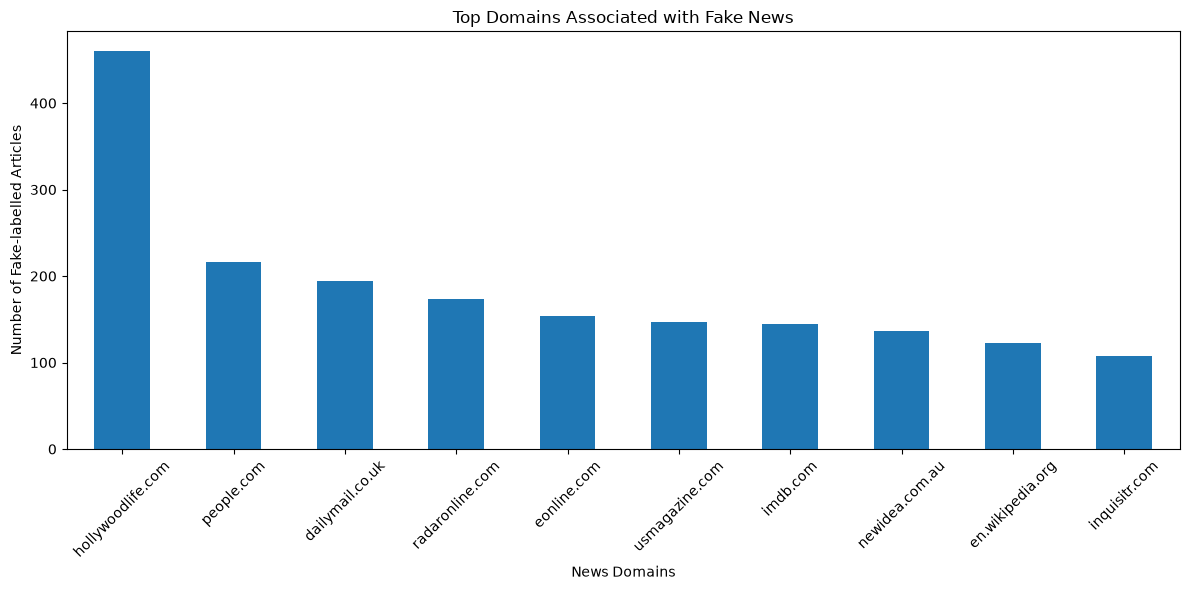

In [14]:
plt.figure(figsize=(12, 6))

fake_domain_analysis['fake_articles'].head(10).plot(
    kind='bar'
)

plt.title("Top Domains Associated with Fake News")
plt.xlabel("News Domains")
plt.ylabel("Number of Fake-labelled Articles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

analyse External Credibility Scores

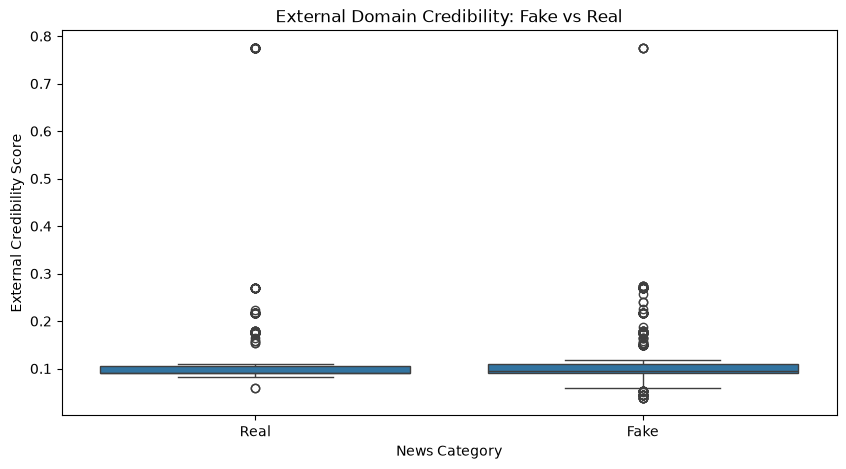

In [15]:
if 'credibility_score' in merged_df.columns:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=merged_df,
        x='label',
        y='credibility_score'
    )

    plt.title("External Domain Credibility: Fake vs Real")
    plt.xlabel("News Category")
    plt.ylabel("External Credibility Score")

    plt.show()

final result

In [16]:
print("DOMAIN CREDIBILITY AND MISINFORMATION ANALYSIS")

print("\nTotal Articles:", len(merged_df))

print("\nUnique Domains:", merged_df['clean_domain'].nunique())

print("\nDomains Matched with External Database:",
      merged_df['credibility_score'].notna().sum()
      if 'credibility_score' in merged_df.columns
      else "Credibility score unavailable")

print("\nTop Fake News Publishing Domains:")
display(fake_domain_analysis.head(10))

print("\nExternal Credibility Information:")
display(merged_df[credibility_columns].head(10))

DOMAIN CREDIBILITY AND MISINFORMATION ANALYSIS

Total Articles: 23196

Unique Domains: 2429

Domains Matched with External Database: 1596

Top Fake News Publishing Domains:


,fake_articles,credibility_score
clean_domain,,
hollywoodlife.com,460,NaN
people.com,216,NaN
dailymail.co.uk,194,0.09
radaronline.com,174,NaN
eonline.com,154,NaN
usmagazine.com,147,NaN
imdb.com,145,NaN
newidea.com.au,137,NaN
en.wikipedia.org,123,NaN



External Credibility Information:


,clean_domain,label,credibility_score,iffy_factual,factcheck_claims,domain_age_years
0,toofab.com,Real,0.11,M,NaN,22.5
1,today.com,Real,NaN,NaN,NaN,NaN
2,etonline.com,Real,NaN,NaN,NaN,NaN
3,dailymail.co.uk,Real,0.09,L,NaN,30.8
4,zerchoo.com,Real,NaN,NaN,NaN,NaN
5,intouchweekly.com,Fake,NaN,NaN,NaN,NaN
6,yournewswire.com,Fake,0.15,L,16.0,11.6
7,etonline.com,Fake,NaN,NaN,NaN,NaN
8,aol.com,Real,NaN,NaN,NaN,NaN
9,98online.com,Real,NaN,NaN,NaN,NaN
